<a href="https://colab.research.google.com/github/Jahura7/Fake-News-Detection-Naive-Bayes/blob/main/Fake_News_Detection_Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Assignment Tasks:**

Prepare  a **Naive Bayes (NB) classification model** using the dataset provided. Your task includes the following steps:

1. Load and explore the dataset.

2. Preprocess the data if required (handle missing values, encode categorical variables, etc.).

3. Split the data into training and testing sets.

4. Build a Naive Bayes model using the training data.

5. Evaluate the model's performance using appropriate metrics (e.g., accuracy, confusion matrix).

6. Interpret the results and provide a brief summary of findings.

In [8]:
import pandas as pd

**Load Dataset**

In [9]:
df = pd.read_csv('fake_or_real_news.csv')


/tmp/ipykernel_715/2698515940.py:1: DtypeWarning: Columns (22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('fake_or_real_news.csv')


**Explore Dataset**

In [10]:
df.head()

,text,label,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 129,Unnamed: 130,Unnamed: 131,Unnamed: 132,Unnamed: 133,Unnamed: 134,Unnamed: 135,Unnamed: 136,Unnamed: 137,Unnamed: 138
0,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,U.S. Secretary of State John F. Kerry said Mon...,REAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,It's primary day in New York and front-runners...,REAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df.tail()

,text,label,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 129,Unnamed: 130,Unnamed: 131,Unnamed: 132,Unnamed: 133,Unnamed: 134,Unnamed: 135,Unnamed: 136,Unnamed: 137,Unnamed: 138
7790,The State Department told the Republican Natio...,REAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7791,The ‘P’ in PBS Should Stand for ‘Plutocratic’ ...,FAKE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7792,Anti-Trump Protesters Are Tools of the Oligar...,FAKE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7793,"ADDIS ABABA, Ethiopia —President Obama convene...",REAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7794,Jeb Bush Is Suddenly Attacking Trump. Here's W...,REAL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7795 entries, 0 to 7794
Columns: 139 entries, text to Unnamed: 138
dtypes: object(139)
memory usage: 8.3+ MB


In [13]:
df.describe()

,text,label,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 129,Unnamed: 130,Unnamed: 131,Unnamed: 132,Unnamed: 133,Unnamed: 134,Unnamed: 135,Unnamed: 136,Unnamed: 137,Unnamed: 138
count,6929,6755,318,241,179,133,91,65,55,38,...,1,1,1,1,1,1,1,1,1,1
unique,6644,437,315,241,179,133,91,65,55,38,...,1,1,1,1,1,1,1,1,1,1
top,"Killing Obama administration rules, dismantlin...",REAL,etc.,bold way,” Maureen Dowd writes. “Before he jumped into ...,Trump was seen as bombastic,vulgar,a bit of a buffoon and a cave man,but [also] ‘a cheeky brio.’ He was not regard...,not a predator … But he created another chara...,...,rather than acting out of a sober evaluation ...,but to me,more and more,the whole shooting match seems to come down t...,if one could discredit the idea of American e...,then it becomes much easier to have a serious...,a presidential candidate,a senator can stand behind the podium and mak...,it just seems that undertaking a serious crit...,REAL
freq,58,3161,3,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


In [14]:
df.shape

(7795, 139)

In [15]:
df.dtypes

,0
text,object
label,object
Unnamed: 2,object
Unnamed: 3,object
Unnamed: 4,object
...,...
Unnamed: 134,object
Unnamed: 135,object
Unnamed: 136,object
Unnamed: 137,object


In [16]:
df.isnull().sum()

,0
text,866
label,1040
Unnamed: 2,7477
Unnamed: 3,7554
Unnamed: 4,7616
...,...
Unnamed: 134,7794
Unnamed: 135,7794
Unnamed: 136,7794
Unnamed: 137,7794


**Select Required Columns**

In [17]:
data = df[['text', 'label']].copy()
data

,text,label
0,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,It's primary day in New York and front-runners...,REAL
...,...,...
7790,The State Department told the Republican Natio...,REAL
7791,The ‘P’ in PBS Should Stand for ‘Plutocratic’ ...,FAKE
7792,Anti-Trump Protesters Are Tools of the Oligar...,FAKE
7793,"ADDIS ABABA, Ethiopia —President Obama convene...",REAL


In [18]:
data.isnull().sum()

,0
text,866
label,1040


**Data Cleaning**

In [19]:
# Handling missing text
data['text'] = data['text'].fillna('')

In [20]:
# Removing missing label
data = data.dropna(subset=['label'])

In [21]:
# Cleaning label values
data['label'] = (
    data['label']
    .astype(str)
    .str.strip()
    .str.upper()
)

/tmp/ipykernel_715/1775386833.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['label'] = (


In [22]:
# Keeping valid classes
data = data[data['label'].isin(['REAL', 'FAKE'])]


In [23]:
# Converting text to string
data['text'] = data['text'].astype(str).str.strip()

In [24]:
# Removing empty text
data = data[data['text'] != '']


In [25]:
# Checking cleaned dataset
print("Cleaned Dataset Shape:", data.shape)

Cleaned Dataset Shape: (6279, 2)


In [26]:
print("Class Distribution:")
print(data['label'].value_counts())



Class Distribution:
label
REAL    3161
FAKE    3118
Name: count, dtype: int64


**Defining X and y**

In [27]:
X = data['text']
y = data['label']


**Spliting data into training and testing data**

In [28]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [29]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5023
Testing samples: 1256


**Building Naive Byse Model**

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

model = Pipeline([
    (
        'tfidf',
        TfidfVectorizer(
            stop_words='english',
            max_df=0.95,
            min_df=2,
            ngram_range=(1, 2)
        )
    ),

    (
        'nb',
        MultinomialNB()
    )
])

**Trainning the Model**

In [31]:
model.fit(X_train, y_train)


Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, min_df=2, ngram_range=(1, 2),
                                 stop_words='english')),
                ('nb', MultinomialNB())])

**Making Predictions**

In [32]:
y_pred = model.predict(X_test)

**Calculating the Model Accuracy**

In [33]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [34]:
# Model Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)


Accuracy: 0.8726114649681529
Accuracy (%): 87.26114649681529


In [35]:
# Classification Report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.98      0.76      0.86       624
        REAL       0.80      0.99      0.89       632

    accuracy                           0.87      1256
   macro avg       0.89      0.87      0.87      1256
weighted avg       0.89      0.87      0.87      1256



In [36]:
# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['FAKE', 'REAL']
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[473 151]
 [  9 623]]


**Vizualization of Confusion Matrix**

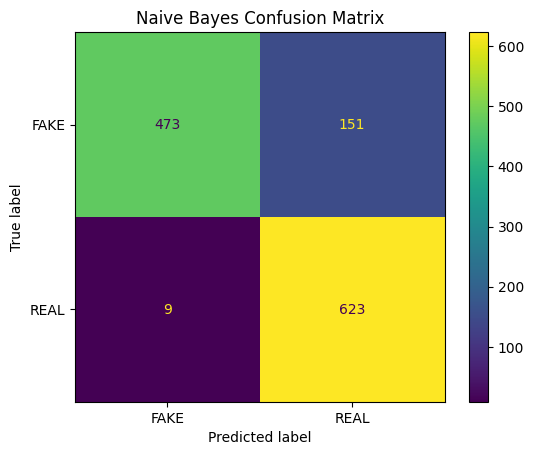

In [37]:
import matplotlib.pyplot as plt


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['FAKE', 'REAL']
)

disp.plot()
plt.title("Naive Bayes Confusion Matrix")
plt.show()

**Interpretation of Result:**

The Naive Bayes model achieved an **accuracy** of approximately **87.26% on the test data**, meaning it correctly classified about 87 out of every 100 test articles.

**REAL recall = 99%**: the model correctly identified almost all REAL articles.

**FAKE precision = 98%**: when the model predicted an article as FAKE, it was usually correct.

However, **FAKE recall = 76%**, meaning some FAKE articles were incorrectly classified as REAL.

The model therefore performs differently for the two classes, which is important to mention rather than relying only on accuracy.




**Conclusion:**

A **Multinomial Naive Bayes classification model** was developed using **TF-IDF features extracted** from the article text.

After preprocessing and removing invalid or missing records, the dataset contained **6,279** usable observations. The data was divided into **80% training** and **20% testing** sets.

The model achieved an **accuracy** of approximately **87.26%** on the test dataset.

The **classification report** and **confusion matrix** show that the model identified REAL articles particularly well, while some FAKE articles were classified as REAL.

Overall, the results demonstrate that Naive Bayes can be an effective baseline model for text-based REAL/FAKE classification.